# My MobApp Studio — complete answer

John wants a market report on the Google Play Store before committing a team to building an app.
His questions, verbatim:

> *What is the size of the market? numbers of download and $*
> *Same question but per category? (percentages please)*
> *Depending on each category, what are the ratio of download per app?*

This notebook is the finished submission: the six functions the project names, the charts it lists,
and the answers to those three questions — with the assumptions each answer rests on.

```
load_dataset()                      print_histograms(dataset)
print_summarize_dataset(dataset)    compute_correlations_matrix(dataset)
clean_dataset(dataset)              print_scatter_matrix(dataset)
```

In [ ]:
# ABOUTME: Complete solution to the Qwasar "My MobApp Studio" project (Google Play market report).
# ABOUTME: Cleaning, analysis functions, the brief's charts, and the market-entry recommendation.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 20)

def _data_path(name="googleplaystore.csv"):
    for up in range(4):
        p = Path(*([".."] * up), "data", name)
        if p.exists():
            return p
    raise FileNotFoundError("run `uv run get_data.py` in workshops/ first")

In [ ]:
def load_dataset():
    """The Google Play export exactly as published."""
    return pd.read_csv(_data_path())

raw = load_dataset()

def print_summarize_dataset(dataset):
    print("Dataset dimension:")
    print(dataset.shape)
    print("\nFirst 10 rows of dataset:")
    print(dataset.head(10))
    print("\nStatistical summary:")
    print(dataset.describe(include="all").head(4))
    print("\nColumn types:")
    print(dataset.dtypes.to_string())

print_summarize_dataset(raw)

Dataset dimension:
(10841, 13)

First 10 rows of dataset:
                                                 App        Category  Rating Reviews  Size     Installs  Type Price Content Rating                     Genres  \
0     Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1     159   19M      10,000+  Free     0       Everyone               Art & Design   
1                                Coloring book moana  ART_AND_DESIGN     3.9     967   14M     500,000+  Free     0       Everyone  Art & Design;Pretend Play   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  ART_AND_DESIGN     4.7   87510  8.7M   5,000,000+  Free     0       Everyone               Art & Design   
3                              Sketch - Draw & Paint  ART_AND_DESIGN     4.5  215644   25M  50,000,000+  Free     0           Teen               Art & Design   
4              Pixel Draw - Number Art Coloring Book  ART_AND_DESIGN     4.3     967  2.8M     100,000+  Free     0       Everyone    Art

Four columns we will need to compute with — **Reviews, Size, Installs, Price** — arrive as `object`,
which is pandas for text. `"10,000+"`, `"19M"`, `"$4.99"`, `"Varies with device"`. Each is a
formatting choice, and each needs a decision.

Before parsing, look for values that cannot exist.

In [ ]:
print("Rating  : min", raw.Rating.min(), "max", raw.Rating.max(), " <- out of 5?")
print("Installs: non-numeric values ->",
      [v for v in raw.Installs.unique() if not str(v).replace(",", "").replace("+", "").isdigit()])
print("Price   : neither $x nor 0 ->",
      sorted({v for v in raw.Price.unique() if not str(v).startswith("$") and str(v) != "0"}))
print("Reviews : not plain digits ->", [v for v in raw.Reviews.unique() if not str(v).isdigit()])
print("Type    :", raw.Type.value_counts(dropna=False).to_dict())
print()
print("every one of those comes from a single row:")
print(raw[~raw.Category.astype(str).str.match(r"^[A-Z_]+$")].to_string())

Rating  : min 1.0 max 19.0  <- out of 5?
Installs: non-numeric values -> ['Free']
Price   : neither $x nor 0 -> ['Everyone']
Reviews : not plain digits -> ['3.0M']
Type    : {'Free': 10039, 'Paid': 800, nan: 1, '0': 1}

every one of those comes from a single row:
                                           App Category  Rating Reviews    Size Installs Type     Price Content Rating             Genres Last Updated Current Ver Android Ver
10472  Life Made WI-Fi Touchscreen Photo Frame      1.9    19.0    3.0M  1,000+     Free    0  Everyone            NaN  February 11, 2018       1.0.19  4.0 and up         NaN


**One corrupt row explains all five anomalies.** Row 10472 lost its Category, so every field after
it shifted one column left: the rating is really a category, `Installs` holds `Free`, `Price` holds
`Everyone`. The Category it lost cannot be recovered, so the row is dropped and the decision noted.

## Cleaning

In [ ]:
def clean_dataset(dataset):
    """Repair the export so it can be computed with. Every step is a decision:

    1. Row 10472 is shifted a column left (no Category) - dropped, not guessed at.
    2. Apps appear more than once because the scraper visited them on different days. One row per
       app, keeping the most-reviewed (most recent) observation. This is the single most
       consequential step: skipping it more than doubles every install total.
    3. Installs ("10,000+") and Price ("$4.99") are text and must become numbers.
    4. Size mixes M, k and "Varies with device" -> megabytes, with "Varies" left missing.
    """
    df = dataset[dataset.Category.astype(str).str.match(r"^[A-Z_]+$")].copy()
    df["Reviews"] = pd.to_numeric(df.Reviews, errors="coerce")
    df = (df.sort_values("Reviews", ascending=False)
            .drop_duplicates(subset="App", keep="first")
            .reset_index(drop=True))
    df["Installs"] = pd.to_numeric(df.Installs.astype(str).str.replace(r"[,+]", "", regex=True),
                                   errors="coerce")
    df["Price"] = pd.to_numeric(df.Price.astype(str).str.replace("$", "", regex=False),
                                errors="coerce")
    size = df.Size.astype(str)
    mb = pd.to_numeric(size.str.rstrip("M"), errors="coerce")
    kb = pd.to_numeric(size.str.rstrip("k"), errors="coerce") / 1024
    df["Size_MB"] = mb.where(size.str.endswith("M"), kb.where(size.str.endswith("k")))
    df["Paid"] = df.Price > 0
    df["Revenue"] = df.Price * df.Installs          # a proxy; see the assumptions at the end
    return df

dataset = clean_dataset(raw)
print(f"{len(raw):,} rows -> {len(dataset):,} apps ({len(raw) - len(dataset):,} removed)")

naive = pd.to_numeric(raw.Installs.astype(str).str.replace(r"[,+]", "", regex=True), errors="coerce").sum()
print(f"\ninstalls if you skip de-duplication: {naive:,.0f}")
print(f"installs after de-duplication      : {dataset.Installs.sum():,.0f}")
print(f"overstatement                      : {naive / dataset.Installs.sum() - 1:+.1%}")

10,841 rows -> 9,659 apps (1,182 removed)

installs if you skip de-duplication: 167,633,433,487
installs after de-duplication      : 75,322,526,427
overstatement                      : +122.6%


**That last number is the headline of the whole project.** Skip one cleaning step and you report a
market more than twice its real size, with a chart to prove it, and nothing in the data complains.

## The required analysis functions

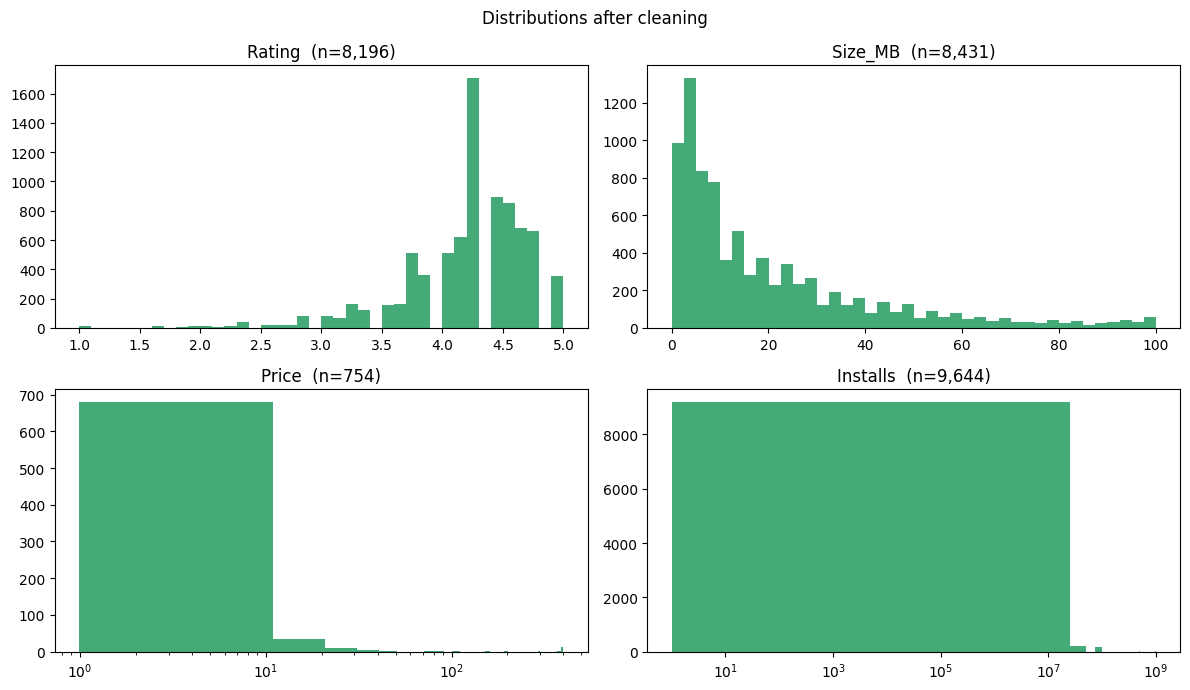

In [ ]:
def print_histograms(dataset):
    """Distributions of the numeric attributes. Counts are log-scaled because they are power laws."""
    cols = ["Rating", "Size_MB", "Price", "Installs"]
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    for ax, col in zip(axes.ravel(), cols):
        data = dataset[col].dropna()
        if col in ("Price", "Installs"):
            data = data[data > 0]
            ax.set_xscale("log")
        ax.hist(data, bins=40, color="#4a7")
        ax.set_title(f"{col}  (n={len(data):,})")
    fig.suptitle("Distributions after cleaning")
    plt.tight_layout()

print_histograms(dataset)

In [ ]:
def compute_correlations_matrix(dataset):
    """Pearson correlations between the numeric attributes."""
    return dataset[["Rating", "Reviews", "Size_MB", "Installs", "Price"]].corr()

correlations = compute_correlations_matrix(dataset)
print(correlations.round(3).to_string())

          Rating  Reviews  Size_MB  Installs  Price
Rating     1.000    0.055    0.063     0.040 -0.021
Reviews    0.055    1.000    0.179     0.625 -0.008
Size_MB    0.063    0.179    1.000     0.134 -0.022
Installs   0.040    0.625    0.134     1.000 -0.009
Price     -0.021   -0.008   -0.022    -0.009  1.000


Only one pair is strongly related: **Reviews and Installs, +0.63** — unsurprising, since reviews
are a by-product of installs. Everything else is near zero, and that is itself the finding:

- **Price does not predict installs** (−0.01). Expensive apps are not systematically less installed.
- **Rating does not predict installs** (+0.04). A 4.7 app is not more downloaded than a 4.2 one.

So "build a highly-rated app and downloads follow" is not supported by this data.

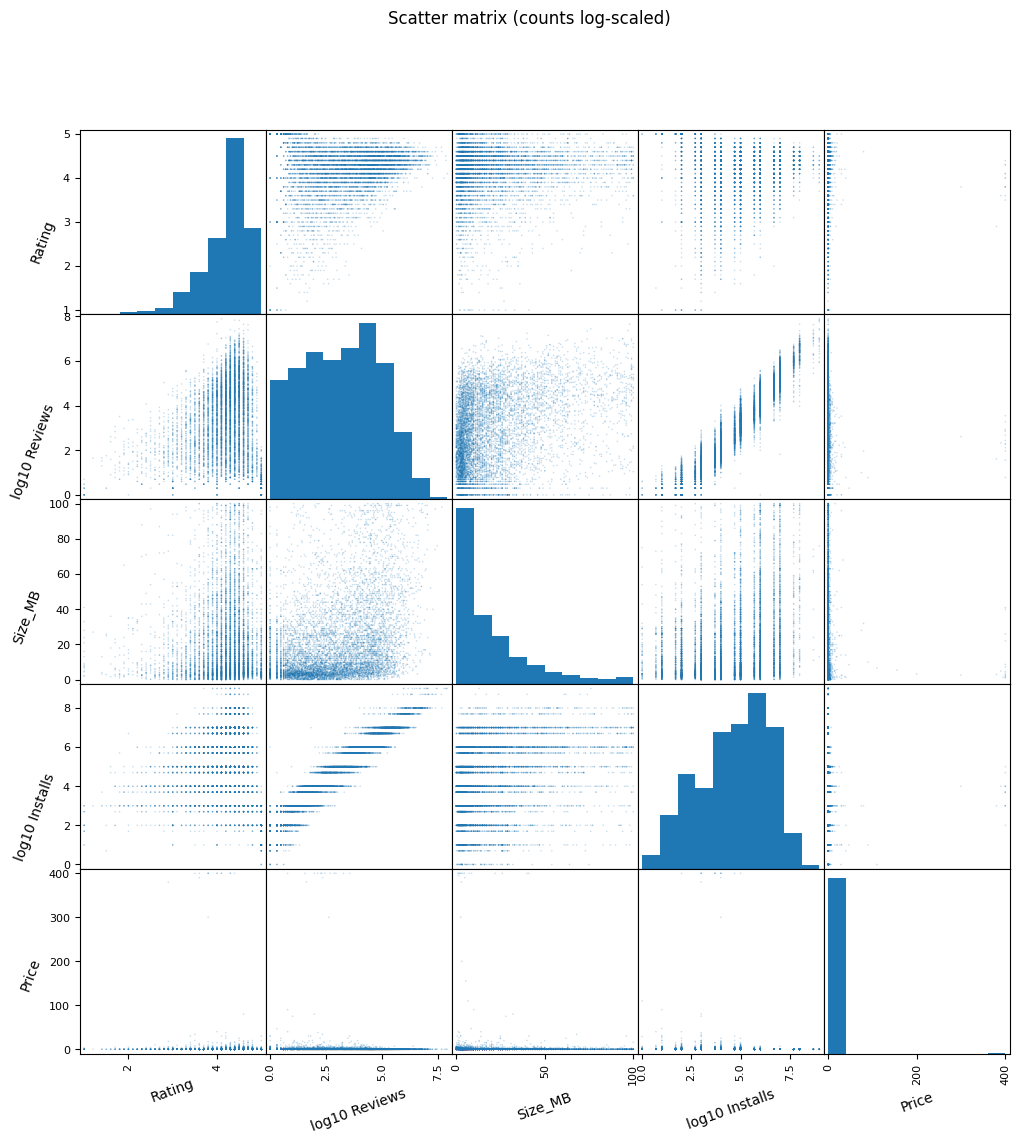

In [ ]:
def print_scatter_matrix(dataset):
    """Every numeric attribute against every other, counts on a log scale."""
    sub = dataset[["Rating", "Reviews", "Size_MB", "Installs", "Price"]].copy()
    for col in ("Reviews", "Installs"):
        sub[col] = np.log10(sub[col].replace(0, np.nan))
    sub = sub.rename(columns={"Reviews": "log10 Reviews", "Installs": "log10 Installs"})
    axes = pd.plotting.scatter_matrix(sub, figsize=(12, 12), diagonal="hist", alpha=0.25, s=5)
    for ax in axes.ravel():
        ax.xaxis.label.set_rotation(20)
        ax.yaxis.label.set_rotation(70); ax.yaxis.label.set_ha("right")
    plt.suptitle("Scatter matrix (counts log-scaled)")

print_scatter_matrix(dataset)

## John's questions

### 1. The size of the market

In [ ]:
total_installs = dataset.Installs.sum()
paid_revenue = dataset.Revenue.sum()
print(f"apps analysed            : {len(dataset):,}  ({int(dataset.Paid.sum()):,} paid)")
print(f"total installs           : {total_installs:,.0f}   (~{total_installs/1e9:.0f} billion)")
print(f"paid-app gross sales     : ${paid_revenue:,.0f}")
print(f"share of installs free   : {dataset.loc[~dataset.Paid, 'Installs'].sum()/total_installs:.2%}")

apps analysed            : 9,659  (754 paid)
total installs           : 75,322,526,427   (~75 billion)
paid-app gross sales     : $291,140,169
share of installs free   : 99.92%


**~75 billion installs, and about $291 million of paid-app sales** — but that dollar figure answers
a narrower question than John asked, and the limitation is the interesting part:

- **99.9 % of installs are free apps.** Their revenue comes from ads and in-app purchases, neither
  of which exists in this dataset. The real market is far larger than $291 M and this data cannot
  see it.
- Installs are published in **buckets** (`10,000+`), so every total is a **lower bound**. Quote
  "roughly 75 billion", never eleven significant digits.

### 2 and 3. Per category: share, and downloads per app

In [ ]:
by_cat = dataset.groupby("Category").agg(apps=("App", "size"),
                                         installs=("Installs", "sum"),
                                         revenue=("Revenue", "sum"),
                                         mean_price=("Price", "mean"))
by_cat["installs_%"] = (100 * by_cat.installs / total_installs).round(2)
by_cat["installs_per_app"] = (by_cat.installs / by_cat.apps).round(0)

print("TOP 10 BY TOTAL INSTALLS")
print(by_cat.nlargest(10, "installs")[["apps", "installs", "installs_%", "installs_per_app"]]
      .to_string(float_format=lambda v: f"{v:,.0f}"))
print("\nTOP 10 BY INSTALLS PER APP (categories with at least 50 apps)")
print(by_cat[by_cat.apps >= 50].nlargest(10, "installs_per_app")[["apps", "installs", "installs_per_app"]]
      .to_string(float_format=lambda v: f"{v:,.0f}"))

TOP 10 BY TOTAL INSTALLS
                    apps     installs  installs_%  installs_per_app
Category                                                           
GAME                 945  13447924415          18        14,230,608
COMMUNICATION        315  11038276251          15        35,042,147
TOOLS                829   8102771915          11         9,774,152
FAMILY              1877   6236542505           8         3,322,612
PRODUCTIVITY         374   5793091369           8        15,489,549
SOCIAL               239   5487867902           7        22,961,790
PHOTOGRAPHY          281   4658147655           6        16,577,038
VIDEO_PLAYERS        164   3931902720           5        23,975,017
TRAVEL_AND_LOCAL     219   2894887146           4        13,218,663
NEWS_AND_MAGAZINES   254   2369217760           3         9,327,629

TOP 10 BY INSTALLS PER APP (categories with at least 50 apps)
                    apps     installs  installs_per_app
Category                                

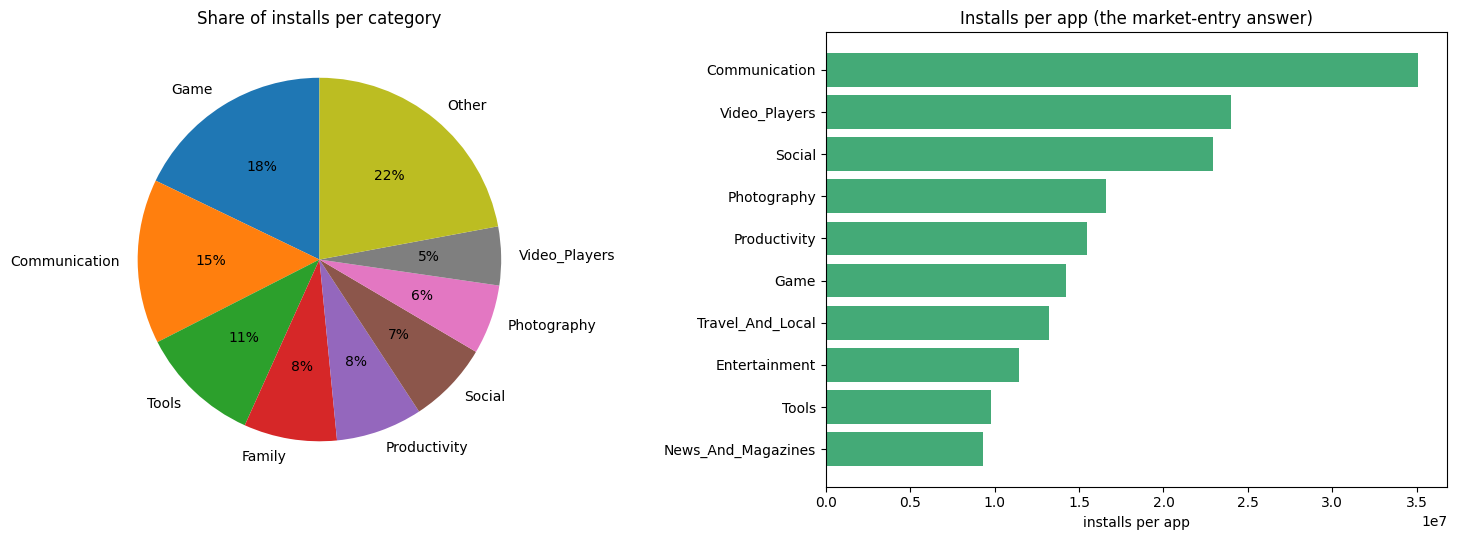

In [ ]:
big = by_cat[by_cat.apps >= 50]
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
top8 = by_cat.installs.nlargest(8)
axes[0].pie(list(top8) + [by_cat.installs.sum() - top8.sum()],
            labels=[c.title() for c in top8.index] + ["Other"], autopct="%1.0f%%", startangle=90)
axes[0].set_title("Share of installs per category")
ratio = big.installs_per_app.nlargest(10)
axes[1].barh([c.title() for c in ratio.index][::-1], ratio.values[::-1], color="#4a7")
axes[1].set_xlabel("installs per app"); axes[1].set_title("Installs per app (the market-entry answer)")
plt.tight_layout()

**The two charts disagree, and that is the recommendation.**

`GAME` wins the pie at **17.9 %** of all installs — and it holds **945 apps**, so the average game
gets about **14 million** installs. `COMMUNICATION` takes a smaller slice with only **315 apps**,
and the average app there gets **35 million** — two and a half times better odds for one new entrant.

Totals describe the market. Ratios describe *your* chances in it, and John asked which market to
enter.

### Revenue per category

                 apps     revenue     installs
Category                                      
FAMILY           1877 115,680,835   6236542505
LIFESTYLE         369  57,583,939    503823539
GAME              945  40,688,637  13447924415
FINANCE           345  25,726,679    455348734
PHOTOGRAPHY       281   8,547,768   4658147655
PERSONALIZATION   376   6,796,948   1532494782
MEDICAL           395   5,956,237     38293077
TOOLS             829   5,464,821   8102771915
SPORTS            325   4,706,212   1096474498
PRODUCTIVITY      374   4,313,375   5793091369


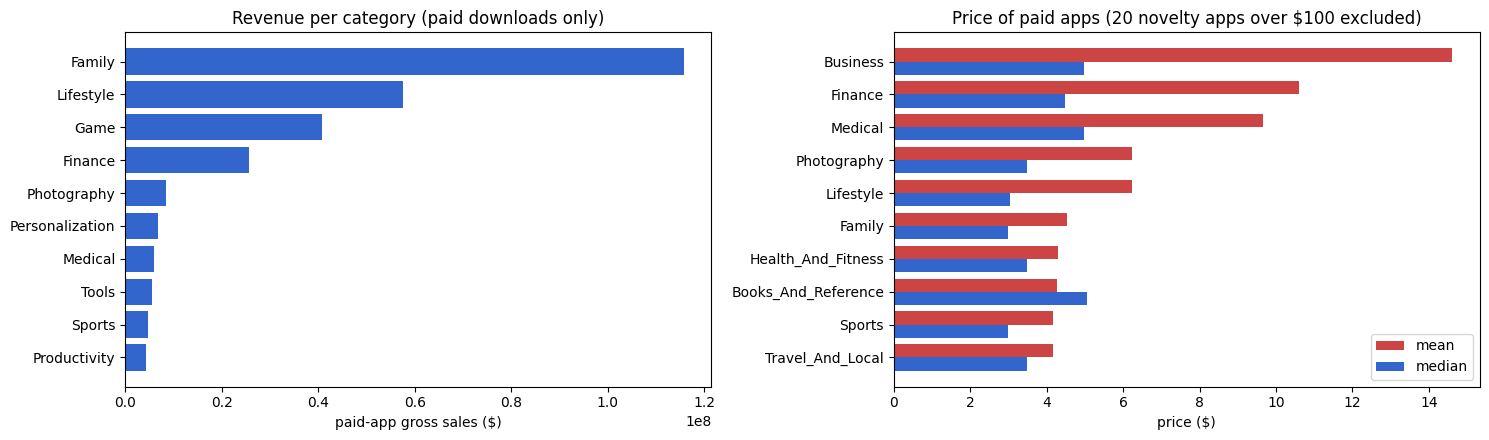

In [ ]:
rev = by_cat[by_cat.revenue > 0].nlargest(10, "revenue")
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].barh([c.title() for c in rev.index][::-1], rev.revenue.values[::-1], color="#36c")
axes[0].set_xlabel("paid-app gross sales ($)"); axes[0].set_title("Revenue per category (paid downloads only)")

paid = dataset[dataset.Paid]
real = paid[paid.Price <= 100]
summary = real.groupby("Category").Price.agg(["mean", "median", "size"]).query("size >= 10").nlargest(10, "mean")
y = np.arange(len(summary))
axes[1].barh(y - 0.2, summary["mean"], height=0.4, label="mean", color="#c44")
axes[1].barh(y + 0.2, summary["median"], height=0.4, label="median", color="#36c")
axes[1].set_yticks(y, [c.title() for c in summary.index]); axes[1].invert_yaxis()
axes[1].set_xlabel("price ($)")
axes[1].set_title(f"Price of paid apps ({len(paid[paid.Price > 100])} novelty apps over $100 excluded)")
axes[1].legend()
plt.tight_layout()
print(rev[["apps", "revenue", "installs"]].to_string(float_format=lambda v: f"{v:,.0f}"))

A trap worth naming, because the brief asks for "the mean price per category" and that chart is
misleading as specified: the dataset contains **20 novelty apps** — `I am rich`,
`I'm Rich - Trump Edition` — priced $300–400. They drag `FINANCE` to a mean of **$8.41** against a
median of **$0.00**. Excluding them and averaging only paid apps reorders the ranking completely,
and the chart above says so in its title.

### The Family category, as the brief asks

paid Family apps: 185

most expensive app per category (top 5):
    Category                      App  Price  Installs
   LIFESTYLE I'm Rich - Trump Edition 400.00     10000
      FAMILY           I am Rich Plus 399.99     10000
     FINANCE        I Am Rich Premium 399.99     50000
     MEDICAL             EP Cook Book 200.00         0
PRODUCTIVITY            cronometra-br 154.99         0


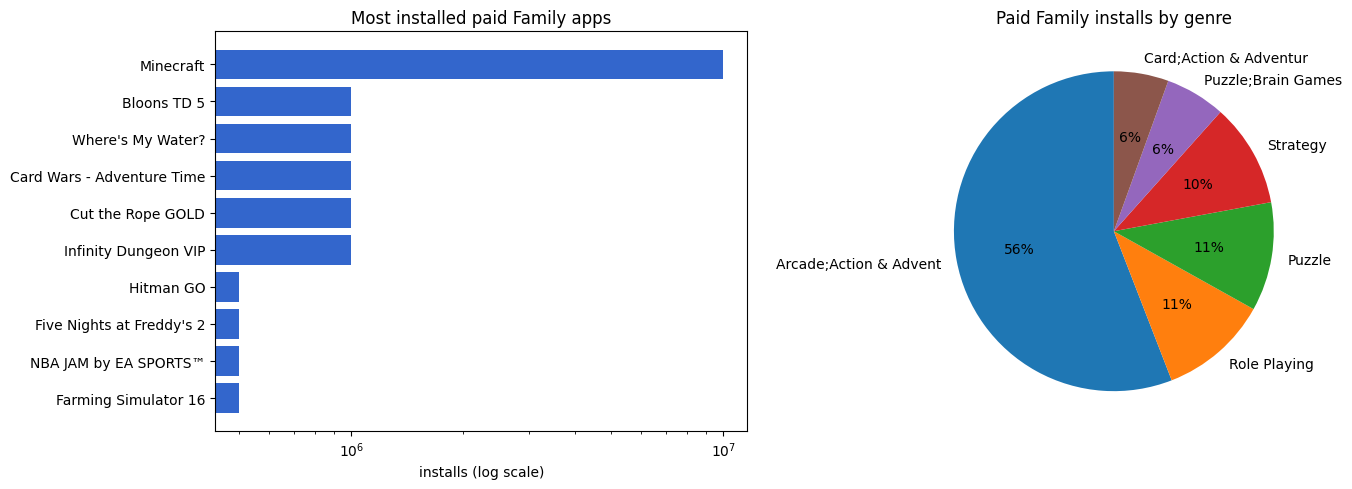

In [ ]:
fam_paid = dataset[(dataset.Category == "FAMILY") & dataset.Paid]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top = fam_paid.nlargest(10, "Installs")
axes[0].barh([a[:28] for a in top.App][::-1], top.Installs.values[::-1], color="#36c")
axes[0].set_xscale("log"); axes[0].set_xlabel("installs (log scale)")
axes[0].set_title("Most installed paid Family apps")
genre = fam_paid.groupby("Genres").Installs.sum().nlargest(6)
axes[1].pie(genre, labels=[g[:22] for g in genre.index], autopct="%1.0f%%", startangle=90)
axes[1].set_title("Paid Family installs by genre")
plt.tight_layout()
print(f"paid Family apps: {len(fam_paid)}")
print("\nmost expensive app per category (top 5):")
print(dataset.loc[dataset.groupby("Category").Price.idxmax()].nlargest(5, "Price")
      [["Category", "App", "Price", "Installs"]].to_string(index=False))

## Recommendation, and what it rests on

**Enter COMMUNICATION, not GAME.** Games take the largest share of installs (17.9 %) but the
category holds 945 apps and the average one reaches 14 M installs. Communication holds 315 apps and
the average reaches 35 M — the best ratio of any category with more than 50 apps. For a studio
shipping *one* app, the ratio is the relevant number.

**Assumptions this rests on** — each of which could change the answer:

1. **Revenue is approximated as price × installs**, ignoring Google's cut, refunds and regional
   pricing, so it overstates what a developer receives.
2. **Install counts are buckets**, so every total is a lower bound and no total is precise.
3. **Only paid sales are counted.** Ads and in-app purchases fund the 99.9 % of installs that are
   free and are invisible here, so the true market is much larger.
4. **This is a 2018 snapshot.** Nothing here says what is growing — and "largest" and
   "fastest-growing" are different recommendations.
5. **Installs per app is an average over a skewed distribution.** Communication's figure is lifted
   by a handful of incumbents (WhatsApp, Messenger); the median app there is far smaller. The
   honest next experiment is to recompute the ratio on the median rather than the mean, which would
   test whether the opportunity is real or an artefact of giants we could never displace.

**Data quality notes for the appendix:** 1 181 duplicate app entries removed (skipping this
overstates installs by 123 %), one malformed row dropped, and 13.6 % of apps carry no rating — those
apps have a median of 1 review against 3 017 for rated apps, so rating averages describe popular
apps, not the store.